# Clustering

Notebook này dùng artifact từ `feature_engineering.ipynb` (text đã được embedding **và đã giảm chiều PCA**) để:
1. Tune tham số bằng Optuna (so sánh GMM vs KMeans).
2. Train pipeline KMeans cuối trên full data.
3. Trực quan hóa cụm bằng t-SNE và UMAP.
4. Áp pipeline cho tập Test, xuất file kết quả.

**Input**:
- `../data/clean/train_processed.parquet`, `../data/clean/test_processed.parquet`
- `../data/clean/X_text_pca_train.npy`, `../data/clean/X_text_pca_test.npy`

**Output**:
- `../models/meta_scaler.joblib`, `../models/kmeans.joblib`
- `../data/clean/Test_with_cluster.csv`

## 1. Load dữ liệu đã xử lý

In [2]:
import numpy as np
import pandas as pd

DATA_DIR  = '../data/clean'
MODEL_DIR = '../models'

Train = pd.read_parquet(f'{DATA_DIR}/train_processed.parquet')
Test  = pd.read_parquet(f'{DATA_DIR}/test_processed.parquet')

X_text_pca_train = np.load(f'{DATA_DIR}/X_text_pca_train.npy')
X_text_pca_test  = np.load(f'{DATA_DIR}/X_text_pca_test.npy')

print('Train             :', Train.shape)
print('Test              :', Test.shape)
print('X_text_pca_train  :', X_text_pca_train.shape)
print('X_text_pca_test   :', X_text_pca_test.shape)

Train             : (453686, 23)
Test              : (56818, 23)
X_text_pca_train  : (453686, 92)
X_text_pca_test   : (56818, 92)


## 2. Chuẩn bị meta features + chuẩn hóa text

Scale các cột numerical (salary_log, experience_level, job_position, education_level), L2-normalize text đã giảm chiều, rồi lấy mẫu 50k để tuning nhanh.

In [3]:
from sklearn.preprocessing import StandardScaler, normalize

numeric_features = ['salary_log', 'experience_level', 'job_position', 'education_level']
X_num_train = Train[numeric_features].values

scaler = StandardScaler()
X_num_scaled_train = scaler.fit_transform(X_num_train)

# L2-normalize text PCA (giúp KMeans/GMM hoạt động giống cosine-similarity)
X_text_norm_train = normalize(X_text_pca_train, norm='l2')

np.random.seed(42)
SAMPLE_SIZE = 50000
sample_idx = np.random.choice(X_text_norm_train.shape[0], size=SAMPLE_SIZE, replace=False)
X_text_sample = X_text_norm_train[sample_idx]
X_num_sample  = X_num_scaled_train[sample_idx]
print('Sample shape:', X_text_sample.shape, X_num_sample.shape)

Sample shape: (50000, 92) (50000, 4)


## 3. Tuning Optuna — GMM

Tune K và trọng số giữa text vs từng cột meta.

In [4]:
import optuna
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

def objective_gmm(trial):
    k        = trial.suggest_int('k', 5, 10)
    w_salary = trial.suggest_float('w_salary', 0.5, 1.0, step=0.5)
    w_exp    = trial.suggest_float('w_exp',    0.5, 1.0, step=0.5)
    w_pos    = trial.suggest_float('w_pos',    0.5, 1.0, step=0.5)
    w_edu    = trial.suggest_float('w_edu',    0.1, 1.5, step=0.2)
    text_weight = trial.suggest_float('text_weight', 0.1, 0.5, step=0.05)

    meta_weights = np.array([w_salary, w_exp, w_pos, w_edu])
    X_combined = np.hstack([X_num_sample * meta_weights, X_text_sample * text_weight])
    X_spherical = normalize(X_combined, norm='l2')

    gmm = GaussianMixture(n_components=k, covariance_type='diag', random_state=42, max_iter=100)
    labels = gmm.fit_predict(X_spherical)
    if len(set(labels)) < 2:
        return -1.0

    sil = silhouette_score(X_spherical, labels, sample_size=5000, random_state=42)
    counts = np.bincount(labels)
    max_ratio = counts.max() / len(labels)
    imbalance = max(0, max_ratio - 0.25)
    trial.set_user_attr('n_clusters', k)
    return sil - imbalance * 0.5

study_gmm = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_gmm.optimize(objective_gmm, n_trials=40, show_progress_bar=True)

print(f'GMM best score: {study_gmm.best_value:.4f}')
print('Params:', study_gmm.best_params)

[I 2026-05-26 13:19:17,900] A new study created in memory with name: no-name-37c7b499-5a24-4c3b-bb9c-384d7a0c05fe


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-05-26 13:19:23,391] Trial 0 finished with value: -0.0769478106376282 and parameters: {'k': 7, 'w_salary': 1.0, 'w_exp': 1.0, 'w_pos': 1.0, 'w_edu': 0.30000000000000004, 'text_weight': 0.15000000000000002}. Best is trial 0 with value: -0.0769478106376282.
[I 2026-05-26 13:19:25,901] Trial 1 finished with value: -0.05838718262900312 and parameters: {'k': 5, 'w_salary': 1.0, 'w_exp': 1.0, 'w_pos': 1.0, 'w_edu': 0.1, 'text_weight': 0.5}. Best is trial 1 with value: -0.05838718262900312.
[I 2026-05-26 13:19:28,021] Trial 2 finished with value: -0.015474075165237218 and parameters: {'k': 9, 'w_salary': 0.5, 'w_exp': 0.5, 'w_pos': 0.5, 'w_edu': 0.5, 'text_weight': 0.30000000000000004}. Best is trial 2 with value: -0.015474075165237218.
[I 2026-05-26 13:19:29,647] Trial 3 finished with value: 0.02832309128121242 and parameters: {'k': 7, 'w_salary': 0.5, 'w_exp': 1.0, 'w_pos': 0.5, 'w_edu': 0.5, 'text_weight': 0.25}. Best is trial 3 with value: 0.02832309128121242.
[I 2026-05-26 13:19:3

## 4. Tuning Optuna — KMeans

Mở rộng range trọng số. Đây là pipeline được chọn để train final.

In [5]:
from sklearn.cluster import KMeans

def objective_kmeans(trial):
    k        = trial.suggest_int('k', 5, 10)
    w_salary = trial.suggest_float('w_salary', 0.1, 1.5, step=0.1)
    w_exp    = trial.suggest_float('w_exp',    0.1, 1.0, step=0.1)
    w_pos    = trial.suggest_float('w_pos',    0.1, 1.0, step=0.1)
    w_edu    = trial.suggest_float('w_edu',    0.1, 1.0, step=0.1)
    text_weight = trial.suggest_float('text_weight', 0.1, 1.0, step=0.05)

    meta_weights = np.array([w_salary, w_exp, w_pos, w_edu])
    X_combined = np.hstack([X_num_sample * meta_weights, X_text_sample * text_weight])
    X_spherical = normalize(X_combined, norm='l2')

    km = KMeans(n_clusters=k, random_state=42, n_init='auto', max_iter=100)
    labels = km.fit_predict(X_spherical)
    if len(set(labels)) < 2:
        return -1.0

    sil = silhouette_score(X_spherical, labels, sample_size=5000, random_state=42)
    counts = np.bincount(labels)
    max_ratio = counts.max() / len(labels)
    imbalance = max(0, max_ratio - 0.25)
    trial.set_user_attr('n_clusters', k)
    return sil - imbalance * 0.5

study_km = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_km.optimize(objective_kmeans, n_trials=40, show_progress_bar=True)

print(f'KMeans best score: {study_km.best_value:.4f}')
print('Params:', study_km.best_params)

[I 2026-05-26 13:20:31,712] A new study created in memory with name: no-name-e41c671e-99ce-49c4-bc57-542c7ebfef13


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-05-26 13:20:32,194] Trial 0 finished with value: 0.3209018233757972 and parameters: {'k': 7, 'w_salary': 1.5, 'w_exp': 0.8, 'w_pos': 0.6, 'w_edu': 0.2, 'text_weight': 0.2}. Best is trial 0 with value: 0.3209018233757972.
[I 2026-05-26 13:20:32,660] Trial 1 finished with value: 0.1385910511429153 and parameters: {'k': 5, 'w_salary': 1.3000000000000003, 'w_exp': 0.7000000000000001, 'w_pos': 0.8, 'w_edu': 0.1, 'text_weight': 1.0}. Best is trial 0 with value: 0.3209018233757972.
[I 2026-05-26 13:20:33,229] Trial 2 finished with value: 0.07606869131791148 and parameters: {'k': 9, 'w_salary': 0.4, 'w_exp': 0.2, 'w_pos': 0.2, 'w_edu': 0.4, 'text_weight': 0.55}. Best is trial 0 with value: 0.3209018233757972.
[I 2026-05-26 13:20:33,849] Trial 3 finished with value: 0.1562374964757957 and parameters: {'k': 7, 'w_salary': 0.5, 'w_exp': 0.7000000000000001, 'w_pos': 0.2, 'w_edu': 0.30000000000000004, 'text_weight': 0.4}. Best is trial 0 with value: 0.3209018233757972.
[I 2026-05-26 13:20:3

## 5. Train final pipeline trên full data

Lấy params trực tiếp từ `study_km.best_params` (kết quả Optuna ở cell trên).

In [ ]:
import os, time, joblib

# Lấy best params từ Optuna study
try:
    BEST_PARAMS = study_km.best_params
    print('Sử dụng best_params từ study_km vừa chạy:')
except NameError:
    # Fallback: kết quả Optuna đã chạy trước đó (40 trials, score 0.4732)
    BEST_PARAMS = {
        'k': 9,
        'w_salary': 1.5, 'w_exp': 1.0, 'w_pos': 0.1, 'w_edu': 0.5,
        'text_weight': 0.1,
    }
    print('study_km chưa tồn tại → dùng fallback hard-coded BEST_PARAMS:')

print(BEST_PARAMS)

BEST_K           = BEST_PARAMS['k']
BEST_TEXT_WEIGHT = BEST_PARAMS['text_weight']
META_WEIGHTS     = np.array([
    BEST_PARAMS['w_salary'],
    BEST_PARAMS['w_exp'],
    BEST_PARAMS['w_pos'],
    BEST_PARAMS['w_edu'],
])  # thứ tự khớp với numeric_features = [salary_log, experience, job_position, education]

os.makedirs(MODEL_DIR, exist_ok=True)

t0 = time.time()
print('\nLắp ráp ma trận hợp nhất...')
X_combined_full = np.hstack([X_num_scaled_train * META_WEIGHTS,
                             X_text_norm_train  * BEST_TEXT_WEIGHT])
X_spherical_full = normalize(X_combined_full, norm='l2')

print(f'KMeans (K={BEST_K}) trên {X_spherical_full.shape[0]:,} dòng...')
km_final = KMeans(n_clusters=BEST_K, random_state=42, n_init='auto', max_iter=100)
final_labels = km_final.fit_predict(X_spherical_full)
Train['Cluster'] = final_labels

joblib.dump(scaler,      f'{MODEL_DIR}/meta_scaler.joblib')
joblib.dump(km_final,    f'{MODEL_DIR}/kmeans.joblib')
joblib.dump(BEST_PARAMS, f'{MODEL_DIR}/best_params.joblib')   # lưu cả params để reproducible
print(f'Done in {time.time()-t0:.1f}s. Saved scaler + kmeans + best_params → {MODEL_DIR}/')

Sử dụng best_params từ study_km vừa chạy:
{'k': 7, 'w_salary': 1.2000000000000002, 'w_exp': 0.2, 'w_pos': 0.6, 'w_edu': 0.6, 'text_weight': 0.1}

Lắp ráp ma trận hợp nhất...
KMeans (K=7) trên 453,686 dòng...
Done in 1.2s. Saved scaler + kmeans + best_params → ../models/


## 6. Visualization & cluster characterization

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

PLOT_SAMPLE_SIZE = min(20000, X_spherical_full.shape[0])
np.random.seed(42)
plot_idx = np.random.choice(X_spherical_full.shape[0], size=PLOT_SAMPLE_SIZE, replace=False)
X_plot = X_spherical_full[plot_idx]
labels_plot = final_labels[plot_idx]

Đang chạy t-SNE trên 20000 điểm...
t-SNE done in 62.6s


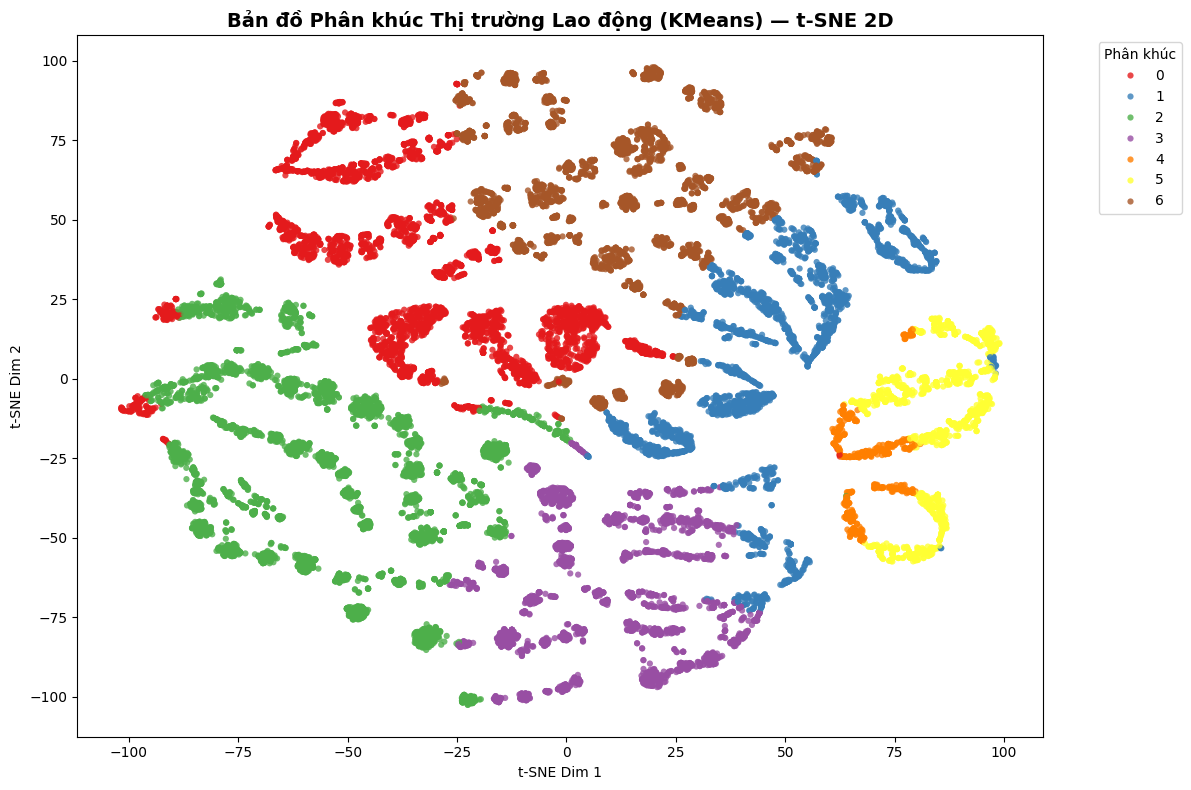

In [8]:
from sklearn.manifold import TSNE

print(f'Đang chạy t-SNE trên {PLOT_SAMPLE_SIZE} điểm...')
t0 = time.time()
tsne = TSNE(n_components=2, perplexity=40, random_state=42, n_jobs=-1)
X_tsne_2d = tsne.fit_transform(X_plot)
print(f't-SNE done in {time.time()-t0:.1f}s')

plt.figure(figsize=(12, 8))
sns.scatterplot(x=X_tsne_2d[:, 0], y=X_tsne_2d[:, 1], hue=labels_plot,
                palette='Set1', s=20, alpha=0.8, edgecolor='none')
plt.title('Bản đồ Phân khúc Thị trường Lao động (KMeans) — t-SNE 2D',
          fontsize=14, fontweight='bold')
plt.xlabel('t-SNE Dim 1'); plt.ylabel('t-SNE Dim 2')
plt.legend(title='Phân khúc', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout(); plt.show()

Đang chạy UMAP trên 20000 điểm...


c:\Users\tranc\AppData\Local\Programs\Python\Python311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP done in 9.4s


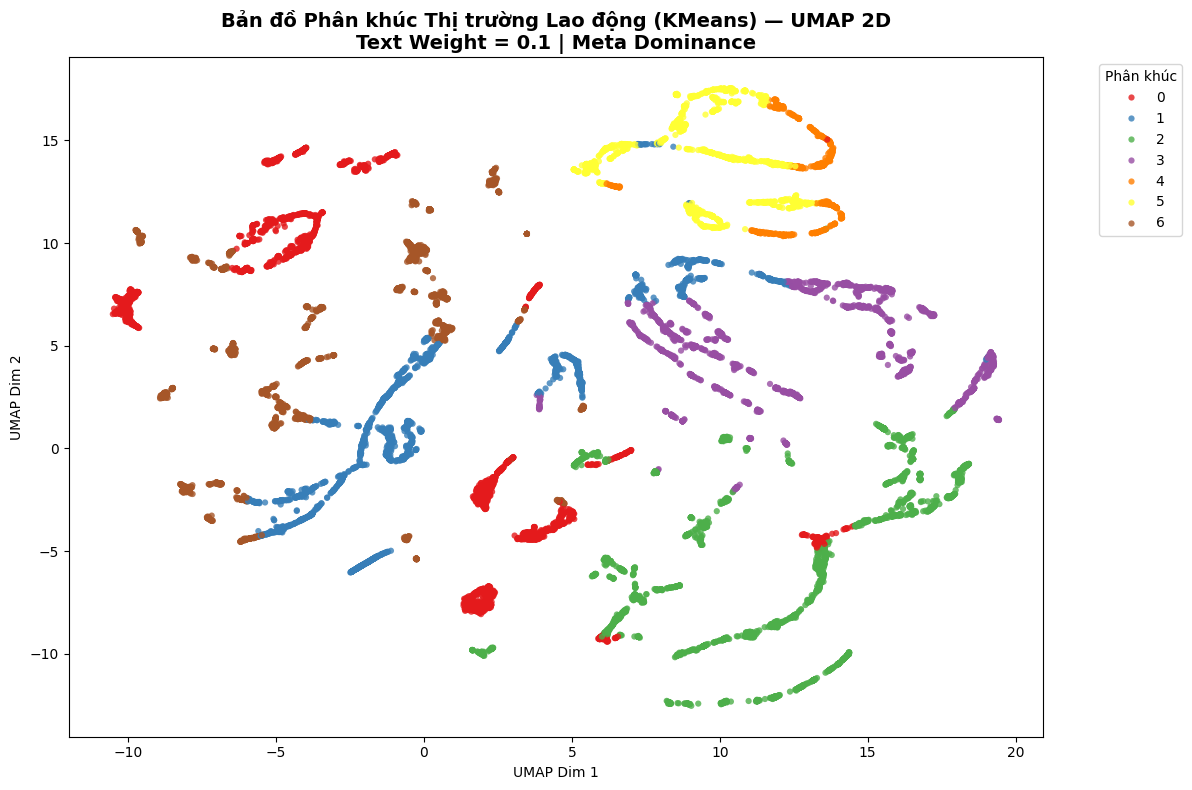

In [13]:
import umap
PLOT_SAMPLE_SIZE_UMAP = 30000
print(f'Đang chạy UMAP trên {PLOT_SAMPLE_SIZE} điểm...')
t0 = time.time()
reducer = umap.UMAP(n_components=2, metric='cosine', random_state=42)
X_umap_2d = reducer.fit_transform(X_plot)
print(f'UMAP done in {time.time()-t0:.1f}s')

plt.figure(figsize=(12, 8))
sns.scatterplot(x=X_umap_2d[:, 0], y=X_umap_2d[:, 1], hue=labels_plot,
                palette='Set1', s=20, alpha=0.8, edgecolor='none')
plt.title(f'Bản đồ Phân khúc Thị trường Lao động (KMeans) — UMAP 2D\n'
          f'Text Weight = {BEST_TEXT_WEIGHT} | Meta Dominance',
          fontsize=14, fontweight='bold')
plt.xlabel('UMAP Dim 1'); plt.ylabel('UMAP Dim 2')
plt.legend(title='Phân khúc', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout(); plt.show()